# Landmark-based registration

TODO: 
- Ajouter description avec schéma de la procédure
- voir avec Eric si on peut améliorer la précision de l'alignement des landmarks?
- Les landmarks optics recalés sur l'IRM ne correspondent pas exactement à ceux de l'IRM.

# Set filenames

In [13]:
# Import libraries and functions
# import matplotlib
# matplotlib.use('TkAgg')

from ITK import *
from utils import *
import os
import tkinter as tk
from tkinter import filedialog
import cv2 as cv
import matplotlib.pyplot as plt
from skimage.transform import pyramid_reduce
from skimage.exposure import match_histograms
import nibabel as nib
from scipy import signal
import glob
import scipy.io as sio

# Indicate the path where MR volumes and optical images are located
Patient_date = "P_026"


main_path = "/home/caredda/Videos/Optical_MRI_data/" + Patient_date

path_MRI_Sainte =  main_path + "/MRI/CHU_Sainté/"
path_neuronavigation_MRI = main_path + "/MRI/HCL/"




# Saving directory
output_dir = main_path +  "/results_registration_landmarks/"
if not os.path.exists(output_dir):
    os.mkdir(output_dir)



# Set filenames fMRI
dir_fMRI_inferences = path_MRI_Sainte + "Condition_Resting-state/Inference_in_brain/"
filename_fMRI_rs_mrean_rHCL = glob.glob(path_MRI_Sainte + "Condition_Resting-state/resting-state mean/*")[0]
filename_fMRI_inferences_rs_rHCL = glob.glob(dir_fMRI_inferences +"*")
print(filename_fMRI_inferences_rs_rHCL)


# Set filename MRI HCL
filename_MRI_HCL = path_neuronavigation_MRI + "FLAIR.nii"
filename_MRI_HCL_surface_mask_brain = output_dir + "surface_mask.nii.gz"
filename_MRI_HCL_brain = output_dir + "FLAIR_bet.nii"
filename_MRI_HCL_mask_brain = output_dir + "FLAIR_bet_mask.nii.gz"


# Set filename optics
filename_Optics_img = main_path + "/optics/initial_img.png"
filename_Optics_mask = main_path + "/optics/mask.png"



# Set filename neuronavigation files
l = glob.glob(path_neuronavigation_MRI+"Condition_Neuronavigation/*.txt")
filename_neuronavigation_MRI = []
for i in range(1,len(l)+1):
    filename_neuronavigation_MRI.append(path_neuronavigation_MRI+"Condition_Neuronavigation/"+str(i)+".txt")


#Get Optics resolution
if not os.path.isfile(main_path + "/optics/resolution.txt"):
    BGR_resolution = 0.064
else:
    BGR_resolution = np.loadtxt(main_path + "/optics/resolution.txt")

BGR_resolution = float(BGR_resolution)

['/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic17.nii', '/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic11.nii', '/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic09.nii', '/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic02.nii', '/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic01.nii', '/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic13.nii', '/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFasti

# Extract brain from anatomical MRI

In [9]:
# # Extract brain using HD-bet
# #Error with HD BET, extracted brain is shifted from MRI
# filename_mask_brain, filename_neuronavigation_MRI_brain = extract_brain(filename_neuronavigation_MRI)

args ='/home/caredda/fsl/bin/bet "'+filename_MRI_HCL+'" "'+filename_MRI_HCL_brain+'" -m -S -B -R -f 0.2'
# print(args)
call(args, shell=True)


0

# Extract surface mask

In [5]:
kernel_size = 7
iterations = (kernel_size - 1) // 2

#Load brain mask
# brain_mask = itk.imread(filename_MRI_HCL_mask_brain, itk.US)
mri_image = nib.load(filename_MRI_HCL_mask_brain)
brain_mask = mri_image.get_fdata()

#Define kernel for erosion
# kernel = StructuringElement(kernelType='Ball', kernelSize=kernel_size, spatialDimension=3)
# Create a ball-shaped structuring element (3x3x3)
kernel = generate_binary_structure(rank=3, connectivity=1)
kernel = iterate_structure(kernel, iterations=iterations)

#erosion
# eroded_mask = ErodeFilter(brain_mask,kernel)
eroded_mask =  binary_erosion(brain_mask, structure=kernel).astype(brain_mask.dtype)

# Apply substraction
# mask_surface = SubtractFilter(brain_mask, eroded_mask)
mask_surface = brain_mask - eroded_mask

# Write surface mask
# itk.imwrite(mask_surface, filename_MRI_HCL_surface_mask_brain)
mask_surface_image = nib.Nifti1Image(mask_surface, affine=mri_image.affine)

# Save the eroded image to a .nii.gz file
nib.save(mask_surface_image, filename_MRI_HCL_surface_mask_brain)

# Register fMRI on HCL MRI

In [2]:
# # Register fMRI volumes to anatomical MRI
# apply_transform_recursively(filename_fixed = filename_MRI_HCL,
#                             filename_moving = filename_fMRI_rs_mrean,
#                             prefix = "r_HCL_",
#                             filename_others = filename_fMRI_inferences_rs,
#                             transform_type = 'affine fMRI',
#                             output_log_dir = output_dir)

Register volumes

  Writing image ...
Apply transform to other volumes


# Landmark registration: Calculate the 2D to 3D and 2D to 3D transforms

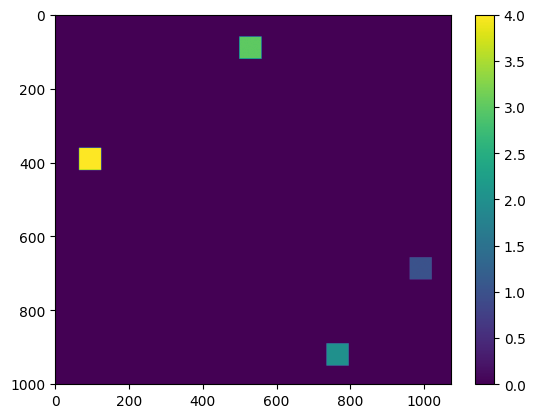

0

In [16]:
###################
# Get MRI landmarks
###################

#Load MRI data
pre_op_MRI = nib.load(filename_MRI_HCL)



#init output
landmarks_MRI = np.zeros(pre_op_MRI.get_fdata().shape, dtype=np.int16)
landmarks_MRI_display = np.zeros(pre_op_MRI.get_fdata().shape, dtype=np.int16)


# Set landmarks
for i in range(len(filename_neuronavigation_MRI)):

    #Load location of landmark in physical space (mm)
    Point = np.loadtxt(filename_neuronavigation_MRI[i]).astype(int)
    x = Point[0]
    y = Point[1]
    z = Point[2]

    # Convert mm coordinates to voxel indices
    affine_matrix = pre_op_MRI.affine
    voxel_coordinates = (np.linalg.inv(affine_matrix) @ np.vstack([x, y, z, np.ones_like(x)])).astype(int)
    
    # Access values at converted voxel coordinates
    x, y, z, a = voxel_coordinates[:, 0]
    G = 5
    landmarks_MRI_display[x-G : x+G, y-G : y+G, z-G : z+G] = i+1
    landmarks_MRI[x, y, z] = i+1
       

#create nii image
img_landmarks_MRI_nii = nib.Nifti1Image(landmarks_MRI, pre_op_MRI.affine)
img_landmarks_MRI_nii.header.set_zooms(pre_op_MRI.header.get_zooms())
#save nii image
nib.save(img_landmarks_MRI_nii,output_dir+"landmarks_MRI.nii")

img_landmarks_MRI_nii = nib.Nifti1Image(landmarks_MRI_display, pre_op_MRI.affine)
img_landmarks_MRI_nii.header.set_zooms(pre_op_MRI.header.get_zooms())
#save nii image
nib.save(img_landmarks_MRI_nii,output_dir+"landmarks_MRI_display.nii")




###################
# Get Optics landmarks
###################

initial_img = cv.imread(filename_Optics_img)
landmarks_Optics_display = np.zeros((initial_img.shape[0],initial_img.shape[1]))

if not os.path.exists(output_dir + "Optical_col_landmarks.txt"):
    raise SystemExit("Optical_col_landmarks.txt is missing. Run create_Optics_landmarks.py")

if not os.path.exists(output_dir + "Optical_row_landmarks.txt"):
    raise SystemExit("Optical_row_landmarks.txt is missing. Run create_Optics_landmarks.py")

#Load x,y points
Optics_x_landmarks = np.loadtxt(output_dir+"Optical_col_landmarks.txt").astype(int)
Optics_y_landmarks = np.loadtxt(output_dir+"Optical_row_landmarks.txt").astype(int)


#Create optical landmarks
landmarks_Optics = np.zeros((1,initial_img.shape[0],initial_img.shape[1]), dtype=np.int16)

#landmarks
for i in range(0,len(Optics_x_landmarks)):
    G = 30
    landmarks_Optics[0,Optics_y_landmarks[i],Optics_x_landmarks[i]] = i+1
    landmarks_Optics_display[Optics_y_landmarks[i]-G : Optics_y_landmarks[i]+G,Optics_x_landmarks[i]-G : Optics_x_landmarks[i]+G] = i+1

#Create nii img
optics_vol = itk.GetImageFromArray(np.ascontiguousarray(landmarks_Optics))
optics_vol.SetSpacing([BGR_resolution,BGR_resolution,1])
itk.imwrite(optics_vol,output_dir+"landmarks_Optics.nii")

cv.imwrite(output_dir+"landmarks_Optics_display.png",landmarks_Optics_display)
plt.imshow(landmarks_Optics_display)
plt.colorbar()
plt.show()


###################
# C3D landmarks registration
###################

# changer dof à 12 pour faire recalage affine
dof = 6 #recalage rigide
# dof = 12 #recalage affine

#Optical to MRI projection
args ='c3d '+output_dir+'landmarks_MRI.nii '+output_dir+'landmarks_Optics.nii -alm ' + str(dof) +' '+output_dir+'Optics_2_MRI_transform.txt'
call(args, shell=True)
    

#MRI to Optical projection
args ='c3d '+output_dir+'landmarks_Optics.nii '+output_dir+'landmarks_MRI.nii -alm ' + str(dof) +' '+output_dir+'MRI_2_Optics_transform.txt'
call(args, shell=True)



# Register Optical data on MRI

In [10]:
#Load transform
transform_file = output_dir+'Optics_2_MRI_transform.txt'



##################################################################
# Register optical landmarks to check validity of the registration


#Load optical data
optical_data = cv.imread(output_dir+"landmarks_Optics_display.png",cv.IMREAD_GRAYSCALE)


#Create optical overlay with a thickness
#The thickness aims to correct the registered slice on the brain surface by applying the mask of the brain surface
optics_filename = output_dir+"landmarks_Optics_display.nii.gz"

create_Optical_overlay(in_data = optical_data,
                       outfilename = optics_filename,
                       filename_template = output_dir+"landmarks_Optics.nii",
                       z_expand=30)

#Process registration
optics_registered_filename = optics_filename.split('.')[0]+"_registered_on_MRI.nii.gz"
args ='c3d '+ filename_MRI_HCL+' '+optics_filename + ' -reslice-matrix '+ transform_file +' -o ' + optics_registered_filename
call(args, shell=True)






#######################
# Register optical mask (surgical window)


#Load optical data
optical_data = cv.imread(filename_Optics_mask,cv.IMREAD_GRAYSCALE)/255

#Create optical overlay with a thickness
#The thickness aims to correct the registered slice on the brain surface by applying the mask of the brain surface
optics_filename = output_dir+"mask_surgical_window.nii.gz"

create_Optical_overlay(in_data = optical_data,
                       outfilename = optics_filename,
                       filename_template = output_dir+"landmarks_Optics.nii",
                       z_expand=2)

#Process registration
optics_registered_filename = optics_filename.split('.')[0]+"_registered_on_MRI.nii.gz"
args ='c3d '+ filename_MRI_HCL+' '+optics_filename + ' -reslice-matrix '+ transform_file +' -o ' + optics_registered_filename
call(args, shell=True)

# # Correct optics registration to match the brain surface
# apply_brain_mask(filename=optics_registered_filename,
#                  filename_brain_mask=filename_MRI_HCL_surface_mask_brain,
#                  output_name="_corr")








#######################
# Register optical seed on MRI


#Load optical data
optical_data = np.zeros(cv.imread(filename_Optics_mask,cv.IMREAD_GRAYSCALE).shape,dtype=np.uint8)
r= 692
c=1046
enlarge = 50

optical_data[r-enlarge :r+enlarge,c-enlarge:c+enlarge] = 1

cv.imwrite(output_dir+"rs_RGB_seed.png",optical_data*255)


#Create optical overlay with a thickness
#The thickness aims to correct the registered slice on the brain surface by applying the mask of the brain surface
optics_filename = output_dir+"rs_RGB_seed.nii.gz"

create_Optical_overlay(in_data = optical_data,
                       outfilename = optics_filename,
                       filename_template = output_dir+"landmarks_Optics.nii",
                       z_expand=1)

#Process registration
optics_registered_filename = optics_filename.split('.')[0]+"_registered_on_MRI.nii.gz"
args ='c3d '+ filename_MRI_HCL+' '+optics_filename + ' -reslice-matrix '+ transform_file +' -o ' + optics_registered_filename
call(args, shell=True)



0

# Register fMRI on Optics

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic17.nii


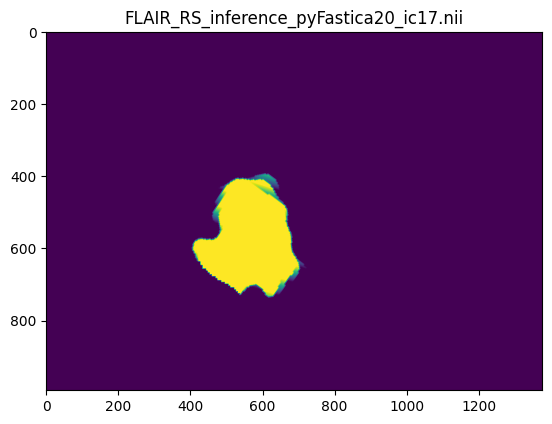

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic11.nii


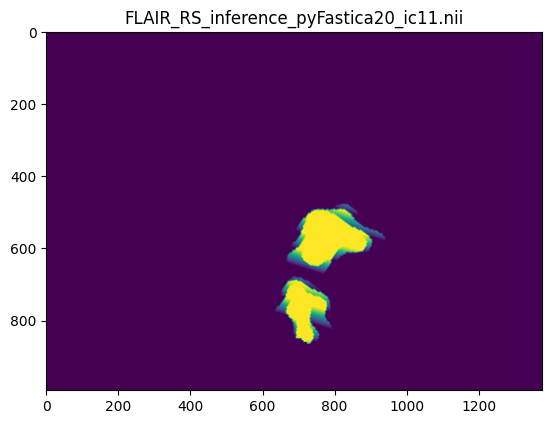

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic09.nii


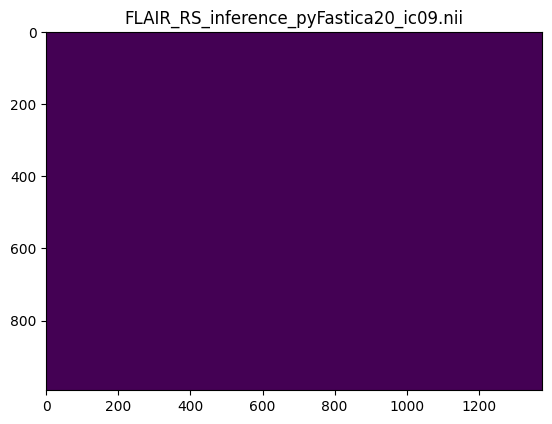

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic02.nii


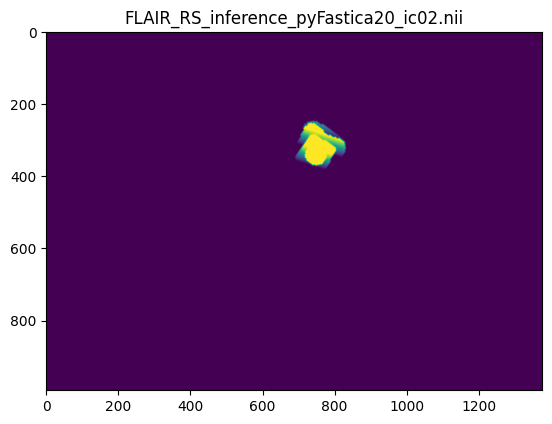

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic01.nii


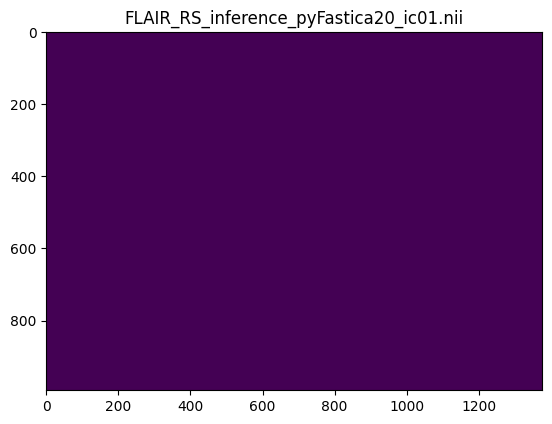

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic13.nii


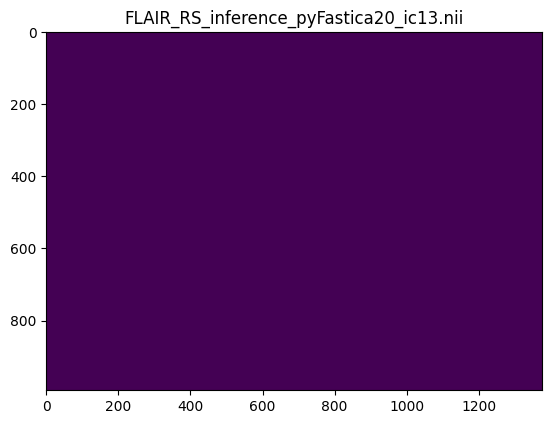

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic19.nii


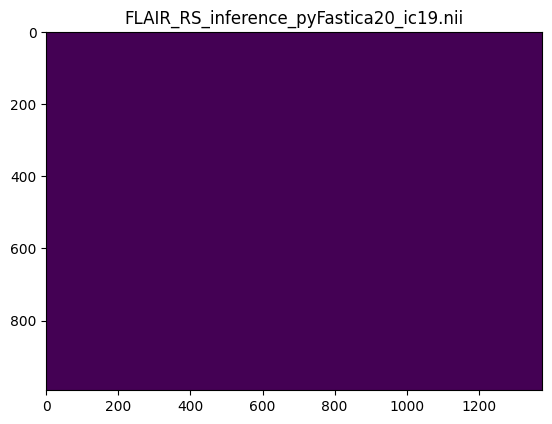

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic12.nii


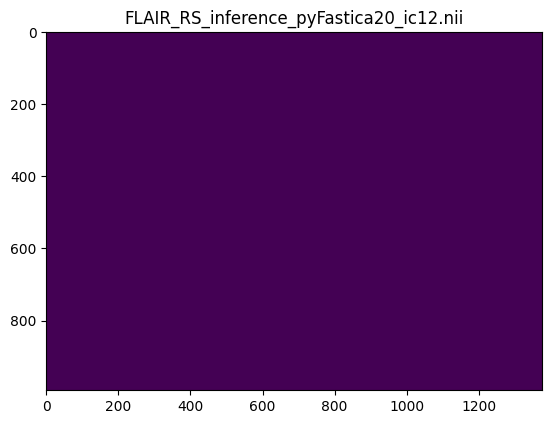

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_seed_Corrected_noMorph.nii


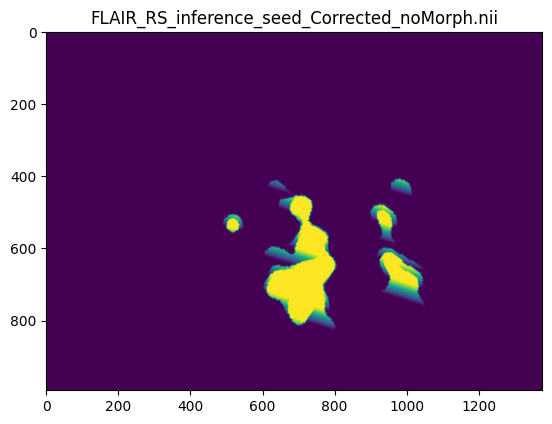

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic20.nii


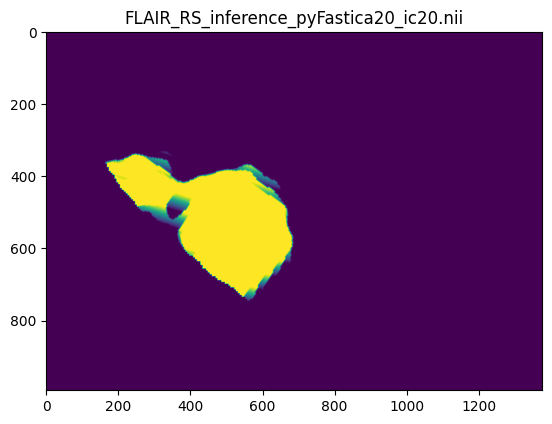

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic18.nii


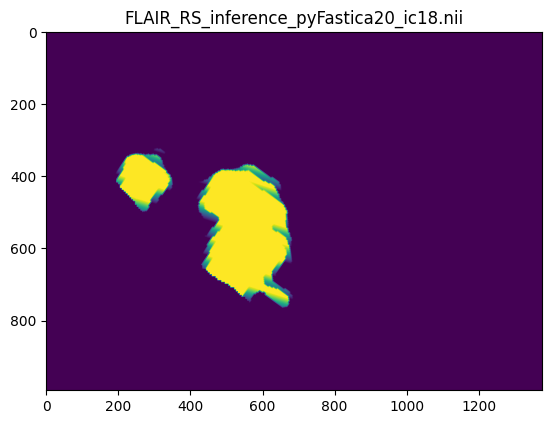

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic04.nii


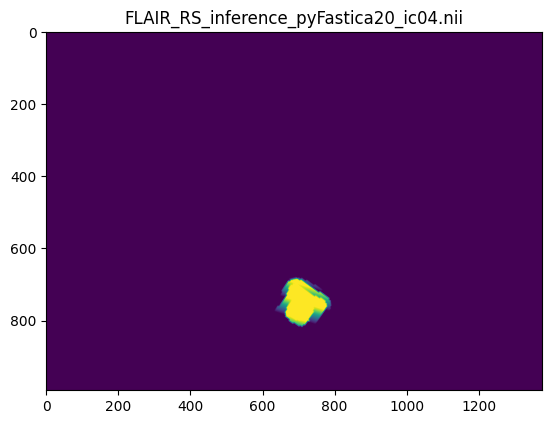

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic08.nii


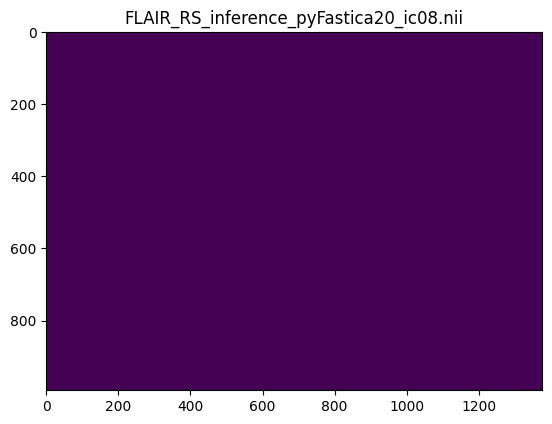

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic05.nii


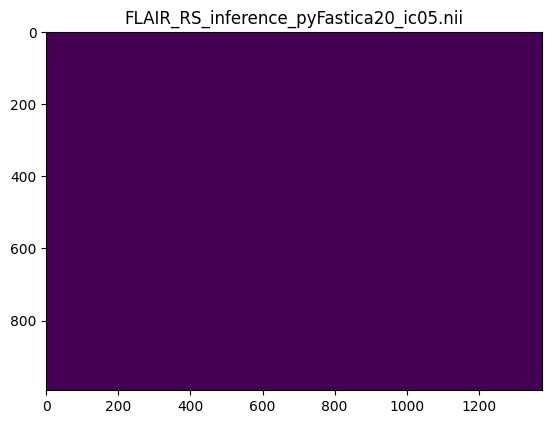

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic06.nii


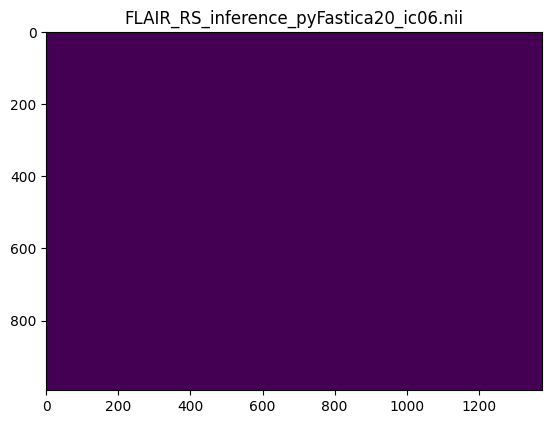

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic07.nii


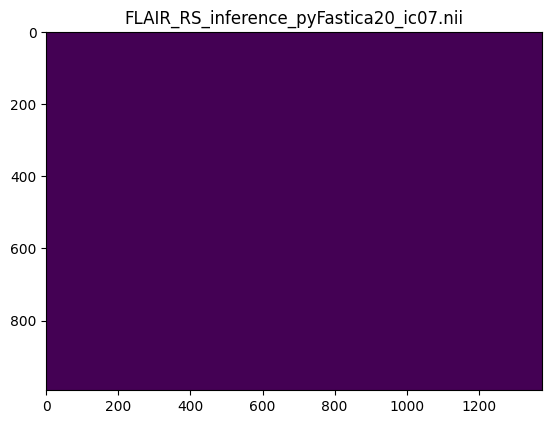

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic03.nii


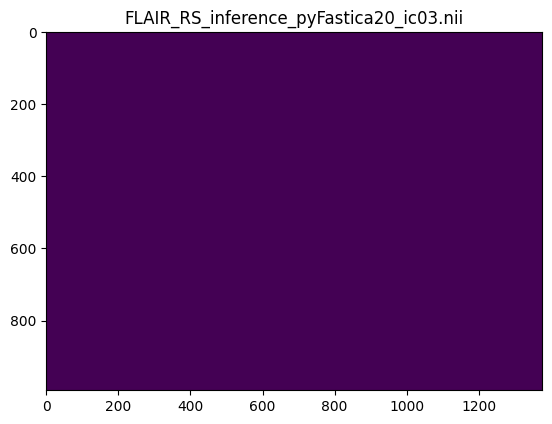

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic10.nii


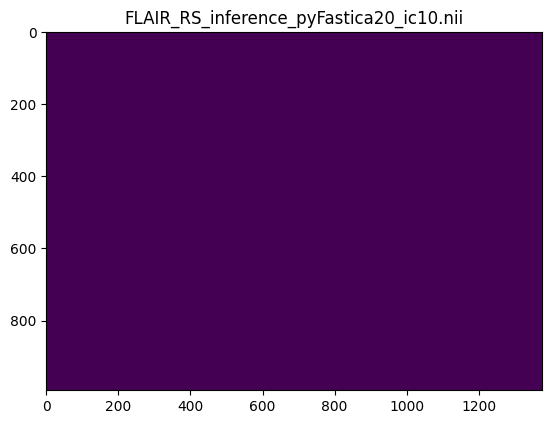

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic14.nii


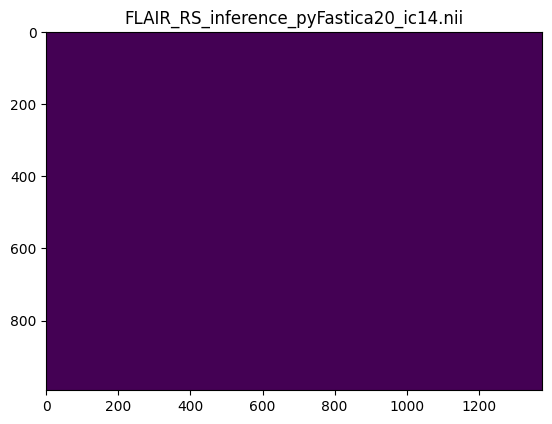

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_seed_Shifted.nii


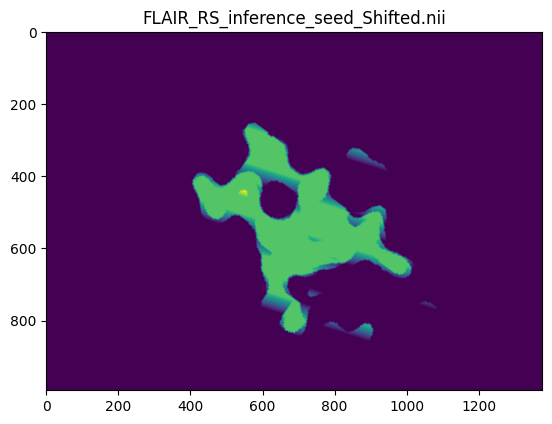

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic16.nii


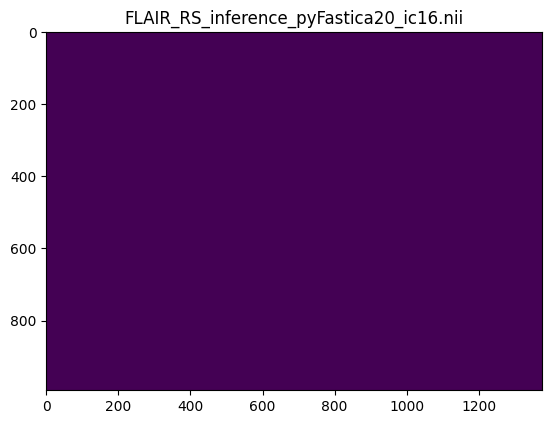

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_pyFastica20_ic15.nii


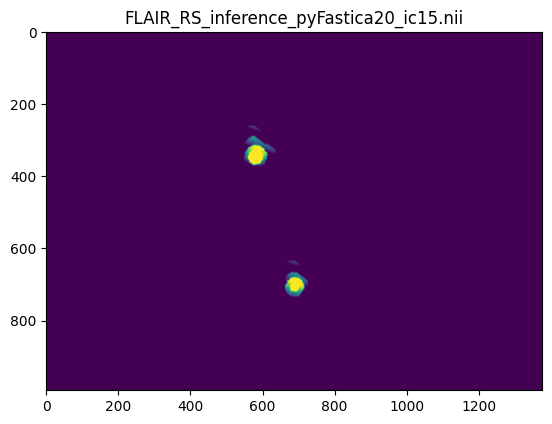

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_seed_Corrected.nii


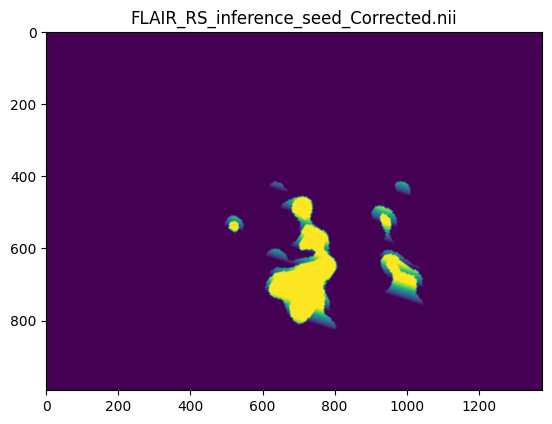

/home/caredda/Videos/Optical_MRI_data/P_026/MRI/CHU_Sainté/Condition_Resting-state/Inference_in_brain/FLAIR_RS_inference_seed_Shifted_NoMorph.nii


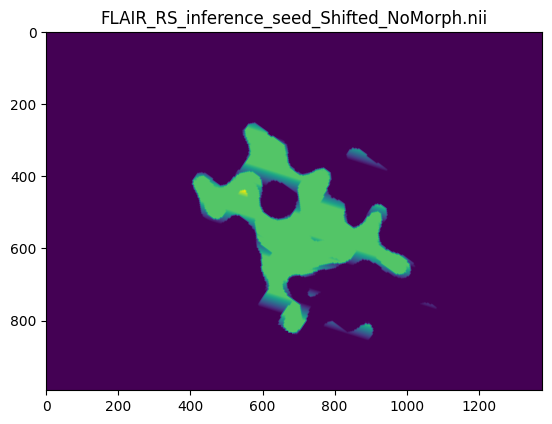

In [14]:
#Create output directory
res_dir = output_dir +  "r_opt_fMRI/"
if not os.path.exists(res_dir):
    os.mkdir(res_dir)


#Transform file
transform_file = output_dir+'MRI_2_Optics_transform.txt'

#Create optics overlay
optical_data = cv.imread(filename_Optics_mask,cv.IMREAD_GRAYSCALE)/255
optics_filename = output_dir+"mask_surgical_window.nii.gz"
create_Optical_overlay(in_data = optical_data,
                       outfilename = optics_filename,
                       filename_template = output_dir+"landmarks_Optics.nii",
                       z_expand=1)


# register fMRI on optics
for f in filename_fMRI_inferences_rs_rHCL:
    
    # Result filename
    res_file = res_dir + "r_opt_" + os.path.basename(f)
    print(f)


    # # Apply brain surface mask to fMRI data
    # apply_brain_mask_nibabel(filename=f,
    #                 filename_brain_mask=filename_MRI_HCL_surface_mask_brain,
    #                 output_name="_brain_surface")


    #Compute registration
    args ='c3d '+optics_filename +' -popas ref '+ f + ' -insert ref 1 -reslice-matrix '+ transform_file + ' -o '+res_file
    call(args, shell=True)


    #Plot fMRI projection
    im = itk.imread(res_file)
    im = optical_data*np.squeeze(itk.GetArrayFromImage(im))
    plt.figure()
    plt.imshow(im)
    plt.title(os.path.basename(f))
    plt.show()

# # #Load fMRI data
# # cartes_IRMf = nib.load(temp_path+"SPM_fMRI_registered_on_Optics.nii")
# # header = cartes_IRMf.header
# # MRIf_volume = np.squeeze(cartes_IRMf.get_fdata())
# # print("fMRI map registered in optical map shape: "+str(MRIf_volume.shape))